# South African Weather Data Analysis 

## 1. Introduction

This notebook analyses weather data collected from nine South African cities using a Python ETL pipeline.

The analysis focuses on three weather measurements:

- **Temperature:** Measured in degrees Celsius (°C).
- **Humidity:** Measured as a percentage (%).
- **Wind speed:** Measured in kilometres per hour (km/h).

### Objectives

1. Inspect the processed weather dataset.
2. Check data quality by identifying missing values and duplicate records.
3. Calculate average weather measurements for each city.
4. Visualise and compare the results using bar charts.
5. Summarise the key findings.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Locate the project directory
project_dir = Path.home() / "Electives" / "South_african_weather_pipeline"

# Define the processed dataset path
csv_path = project_dir / "data" / "processed" / "weather.csv"

# Load the weather dataset
df = pd.read_csv(csv_path)

# Display the first five records
display(df.head())

# Display the dataset size
print("Total records:", len(df))
print("Number of cities:", df["city"].nunique())
print("Columns:", df.columns.tolist())

,city,timestamp,temperature_c,humidity_percent,wind_speed_kmh
0,east_london,2026-10-21T15:00,21.4,63,21.5
1,cape_town,2026-10-14T08:45,16.6,58,17.1
2,east_london,2026-10-20T08:00,20.8,36,8.3
3,mbombela,2026-10-20T13:45,23.9,52,13.7
4,bloemfontein,2026-10-08T11:15,27.0,35,18.4


Total records: 105
Number of cities: 9
Columns: ['city', 'timestamp', 'temperature_c', 'humidity_percent', 'wind_speed_kmh']


In [3]:
# Display the dataset structure
print("Dataset information:")
df.info()

# Display basic statistics
print("\nSummary statistics:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   city              105 non-null    str    
 1   timestamp         105 non-null    str    
 2   temperature_c     105 non-null    float64
 3   humidity_percent  105 non-null    int64  
 4   wind_speed_kmh    105 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 4.2 KB

Summary statistics:


,temperature_c,humidity_percent,wind_speed_kmh
count,105.000000,105.000000,105.000000
mean,24.071429,50.123810,13.521905
std,3.778856,17.152985,5.060100
min,14.900000,9.000000,0.000000
25%,21.400000,36.000000,10.900000
50%,25.200000,55.000000,13.100000
75%,26.900000,63.000000,16.300000
max,32.500000,87.000000,37.000000


## 1. Data Quality Checks

Before analysing the weather data, we will check for missing values and duplicate records to ensure the dataset is suitable for analysis.

In [4]:
# Check for missing values
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Check for completely duplicated rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check for duplicate city and timestamp combinations
print(
    "Duplicate city-timestamp records:",
    df.duplicated(subset=["city", "timestamp"]).sum()
)

Missing values in each column:


,Missing Values
city,0
timestamp,0
temperature_c,0
humidity_percent,0
wind_speed_kmh,0



Number of duplicate rows: 0
Duplicate city-timestamp records: 0


## 2. Weather Analysis by City

This section calculates the average temperature, relative humidity, and wind speed for each city. These measurements will help us compare weather conditions across South Africa.

In [5]:
# Calculate average weather measurements for each city
city_summary = (
    df.groupby("city")
    .agg(
        average_temperature=("temperature_c", "mean"),
        average_humidity=("humidity_percent", "mean"),
        average_wind_speed=("wind_speed_kmh", "mean"),
        total_records=("timestamp", "count")
    )
    .reset_index()
)

# Round averages to two decimal places
city_summary[
    ["average_temperature", "average_humidity", "average_wind_speed"]
] = city_summary[
    ["average_temperature", "average_humidity", "average_wind_speed"]
].round(2)

# Display the summary table
display(city_summary)

,city,average_temperature,average_humidity,average_wind_speed,total_records
0,bloemfontein,21.86,46.42,12.58,12
1,cape_town,16.70,62.10,17.25,10
2,durban,25.62,59.42,14.33,12
3,east_london,25.74,62.82,13.23,11
4,gqeberha,21.94,70.08,15.37,12
5,johannesburg,24.18,31.92,11.50,12
6,mbombela,26.46,55.00,10.09,12
7,polokwane,25.72,40.33,16.94,12
8,pretoria,27.34,26.08,11.00,12


## 3. Weather Data Visualisations

### 3.1 Average Temperature by City

This chart compares the average temperature recorded in each city. The cities are arranged from highest to lowest average temperature.

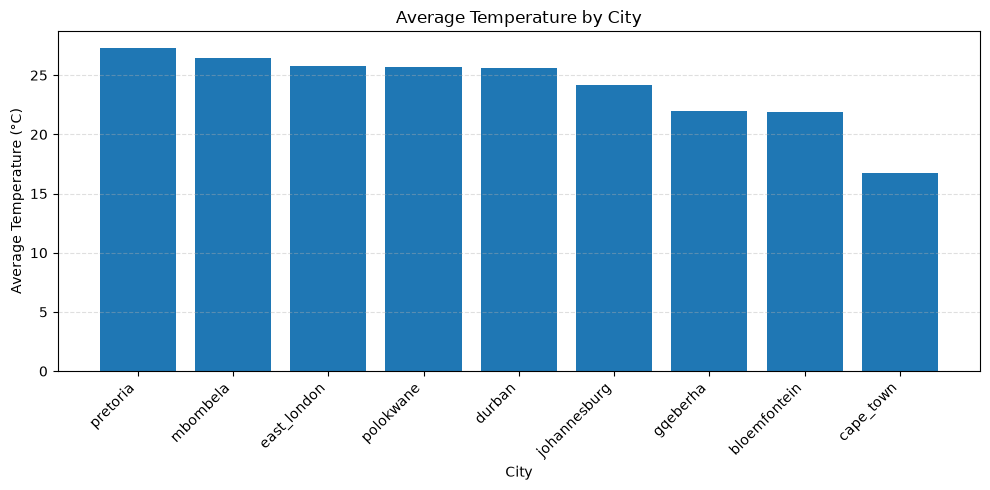

In [6]:
# Sort cities by average temperature, from highest to lowest
temperature_data = city_summary.sort_values(
    by="average_temperature",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    temperature_data["city"],
    temperature_data["average_temperature"]
)

plt.title("Average Temperature by City")
plt.xlabel("City")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.2 Average Humidity by City

This chart compares the average relative humidity recorded in each city, helping us identify differences in moisture levels across the locations.

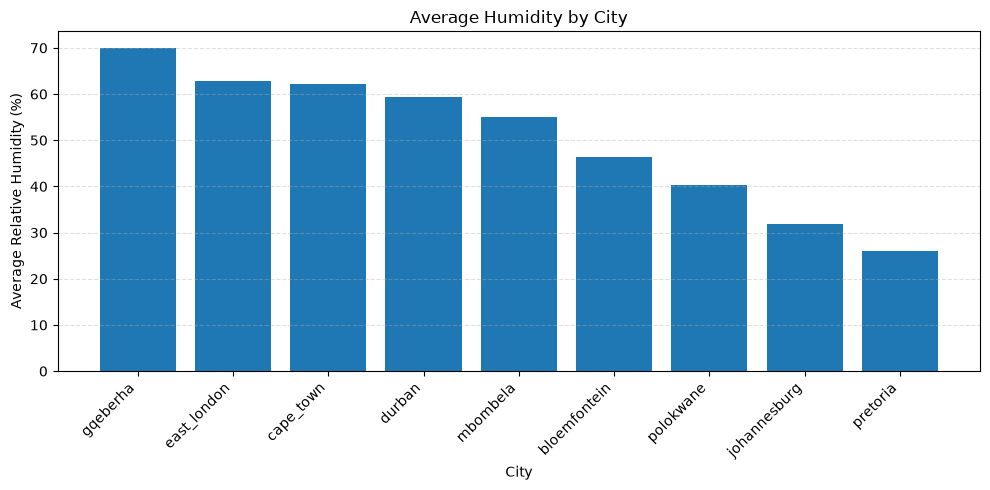

In [7]:
# Sort cities by average humidity, from highest to lowest
humidity_data = city_summary.sort_values(
    by="average_humidity",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    humidity_data["city"],
    humidity_data["average_humidity"]
)

plt.title("Average Humidity by City")
plt.xlabel("City")
plt.ylabel("Average Relative Humidity (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 3.3 Average Wind Speed by City

This chart compares average wind speeds across the nine cities. It helps us identify which locations recorded the highest and lowest average wind speeds in the dataset.

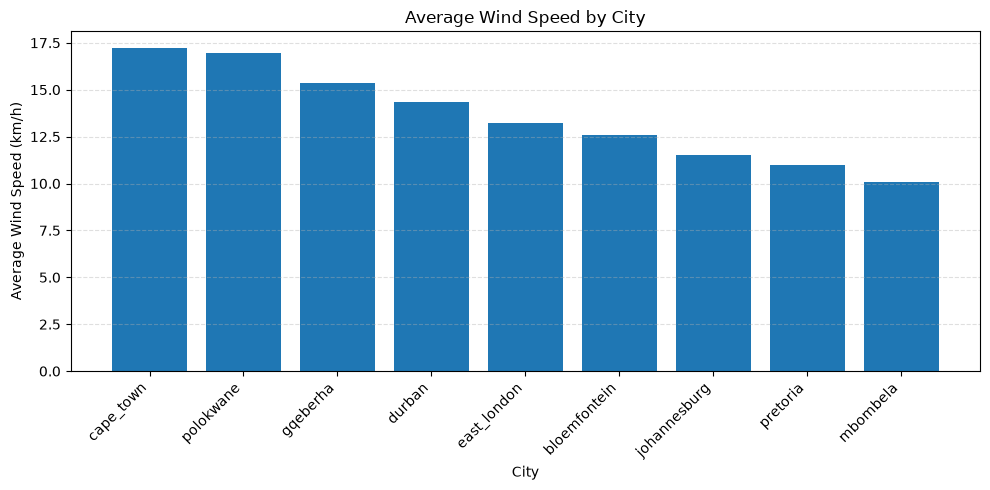

In [8]:
# Sort cities by average wind speed, from highest to lowest
wind_data = city_summary.sort_values(
    by="average_wind_speed",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(
    wind_data["city"],
    wind_data["average_wind_speed"]
)

plt.title("Average Wind Speed by City")
plt.xlabel("City")
plt.ylabel("Average Wind Speed (km/h)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 4. Key Findings

The following results identify the cities with the highest and lowest average temperature, relative humidity, and wind speed.

In [9]:
# Identify the cities with the highest and lowest averages
warmest = city_summary.loc[city_summary["average_temperature"].idxmax()]
coolest = city_summary.loc[city_summary["average_temperature"].idxmin()]

most_humid = city_summary.loc[city_summary["average_humidity"].idxmax()]
least_humid = city_summary.loc[city_summary["average_humidity"].idxmin()]

windiest = city_summary.loc[city_summary["average_wind_speed"].idxmax()]
least_windy = city_summary.loc[city_summary["average_wind_speed"].idxmin()]

# Print the key findings
print("KEY WEATHER FINDINGS")
print("-" * 40)

print(
    f"Highest average temperature: "
    f"{warmest['city'].replace('_', ' ').title()} "
    f"({warmest['average_temperature']:.2f} °C)"
)

print(
    f"Lowest average temperature: "
    f"{coolest['city'].replace('_', ' ').title()} "
    f"({coolest['average_temperature']:.2f} °C)"
)

print(
    f"Highest average humidity: "
    f"{most_humid['city'].replace('_', ' ').title()} "
    f"({most_humid['average_humidity']:.2f}%)"
)

print(
    f"Lowest average humidity: "
    f"{least_humid['city'].replace('_', ' ').title()} "
    f"({least_humid['average_humidity']:.2f}%)"
)

print(
    f"Highest average wind speed: "
    f"{windiest['city'].replace('_', ' ').title()} "
    f"({windiest['average_wind_speed']:.2f} km/h)"
)

print(
    f"Lowest average wind speed: "
    f"{least_windy['city'].replace('_', ' ').title()} "
    f"({least_windy['average_wind_speed']:.2f} km/h)"
)

KEY WEATHER FINDINGS
----------------------------------------
Highest average temperature: Pretoria (27.34 °C)
Lowest average temperature: Cape Town (16.70 °C)
Highest average humidity: Gqeberha (70.08%)
Lowest average humidity: Pretoria (26.08%)
Highest average wind speed: Cape Town (17.25 km/h)
Lowest average wind speed: Mbombela (10.09 km/h)


## 4. Key Findings

This section identifies the cities with the highest and lowest average temperatures, relative humidity, and wind speeds based on the collected weather data.

In [10]:
# Identify the highest and lowest average measurements
warmest = city_summary.loc[city_summary["average_temperature"].idxmax()]
coolest = city_summary.loc[city_summary["average_temperature"].idxmin()]

most_humid = city_summary.loc[city_summary["average_humidity"].idxmax()]
least_humid = city_summary.loc[city_summary["average_humidity"].idxmin()]

windiest = city_summary.loc[city_summary["average_wind_speed"].idxmax()]
least_windy = city_summary.loc[city_summary["average_wind_speed"].idxmin()]

# Display the findings
print("KEY WEATHER FINDINGS")
print("-" * 40)

print(
    f"Warmest city: {warmest['city'].replace('_', ' ').title()} "
    f"({warmest['average_temperature']:.2f} °C)"
)

print(
    f"Coolest city: {coolest['city'].replace('_', ' ').title()} "
    f"({coolest['average_temperature']:.2f} °C)"
)

print(
    f"Highest average humidity: {most_humid['city'].replace('_', ' ').title()} "
    f"({most_humid['average_humidity']:.2f}%)"
)

print(
    f"Lowest average humidity: {least_humid['city'].replace('_', ' ').title()} "
    f"({least_humid['average_humidity']:.2f}%)"
)

print(
    f"Highest average wind speed: {windiest['city'].replace('_', ' ').title()} "
    f"({windiest['average_wind_speed']:.2f} km/h)"
)

print(
    f"Lowest average wind speed: {least_windy['city'].replace('_', ' ').title()} "
    f"({least_windy['average_wind_speed']:.2f} km/h)"
)

KEY WEATHER FINDINGS
----------------------------------------
Warmest city: Pretoria (27.34 °C)
Coolest city: Cape Town (16.70 °C)
Highest average humidity: Gqeberha (70.08%)
Lowest average humidity: Pretoria (26.08%)
Highest average wind speed: Cape Town (17.25 km/h)
Lowest average wind speed: Mbombela (10.09 km/h)


## 5. Conclusion

This notebook analysed weather observations collected from nine South African cities as part of the South African Weather Pipeline project.

The dataset was loaded using Pandas and checked for missing values and duplicate records. The quality checks found no missing values or duplicate records in the dataset.

Average temperature, relative humidity, and wind speed were calculated for each city. Matplotlib was then used to create three bar charts to compare these weather measurements.

The analysis found that Pretoria had the highest average temperature, Gqeberha had the highest average relative humidity, and Cape Town had the highest average wind speed among the cities analysed.

This project demonstrates how Python can be used to process, analyse, and visualise weather data. The findings represent the collected observations and should not be interpreted as long-term climate averages.